# [GSE145705](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE145705)

> - Author: Cao Qiang
> - Email: qiangcao2014@gmail.com
> - Create: 2021-03-13
> - Modified: 2025-05-17

# 1. Experimental Design

> ANP32E Restricts Widespread Chromatin Accessibility Through Regulation of H2A.Z.
> - Murphy, K.E., Meng, F.W., Makowski, C.E. et al. Genome-wide chromatin accessibility is restricted by ANP32E. Nat Commun 11, 5063 (2020). https://doi.org/10.1038/s41467-020-18821-x.
> - ATAC-seq
> - mm10

| Sample | Organism | Source | Genotype | Replicate |
| - | - | - | - | - |
| WT | Mus musculus | Embryonic fibroblasts | Wild Type | rep1~3 |
| KO | Mus musculus | Embryonic fibroblasts | Anp32e KO | rep1~3 |

In [ ]:
library(tidyverse)
suppressPackageStartupMessages({
    library(rtracklayer)
    library(GenomeInfoDb)
    library(GenomicRanges)
    library(EnrichedHeatmap)
    library(RColorBrewer)
    library(viridis)
    library(cowplot)
    library(ggpubr)
})

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.3     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


In [2]:
data_dir <- "~/dataset_1/bulk_omics/atacseq_Mm_mEF_Anp32e_GSE145705"

gtf_file <- "~/reference/Mus_musculus/mm10/gencode.vM23.annotation.gtf"
blacklist_file <- "~/reference/Database/Blacklist/lists/mm10-blacklist.v2.bed"

suppressPackageStartupMessages(library(BSgenome.Mmusculus.UCSC.mm10))
genome <- BSgenome.Mmusculus.UCSC.mm10

In [ ]:
# load reference gene anntotion
gtf <- import(gtf_file) |>
    BRGenomics::tidyChromosomes(keep.X = TRUE, keep.Y = TRUE, keep.M = FALSE)

txdb <- txdbmaker::makeTxDbFromGRanges(
    gtf, drop.stop.codons = TRUE, taxonomyId = 10090, 
    metadata = data.frame(
        name = c("Genome", "Gencode Release"),
        value = c("mm10", "vM23")))

Warning message in .get_cds_IDX(mcols0$type, mcols0$phase):
“The "phase" metadata column contains non-NA values for features of type
  stop_codon. This information was ignored.”
Warning message in .makeTxDb_normarg_chrominfo(chrominfo):
“genome version information is not available for this TxDb object”


# 2. Data Import

## 1). narrowPeak Import

In [4]:
source("~/biology_knowledge_base/06_analysis/00_script/r/01_data_import/load_peaks.R")

In [ ]:
peaks_files <- file.path(data_dir, "04_output_atacseq", "05_peaks") |>
    list.files(pattern = "_peaks\\.narrowPeak$", full.names = TRUE) |>
    set_names(~ sub(
        "(.*)_peaks\\.narrowPeak$", "\\1", basename(.x)))

paste(names(peaks_files), basename(peaks_files), sep = ": ") |> 
    head() |> cat(sep = "\n")

Anp32e_KO_rep1: mEF_Anp32e_KO_rep1_peaks.narrowPeak
Anp32e_KO_rep2: mEF_Anp32e_KO_rep2_peaks.narrowPeak
Anp32e_KO_rep3: mEF_Anp32e_KO_rep3_peaks.narrowPeak
Anp32e_WT_rep1: mEF_Anp32e_WT_rep1_peaks.narrowPeak
Anp32e_WT_rep2: mEF_Anp32e_WT_rep2_peaks.narrowPeak
Anp32e_WT_rep3: mEF_Anp32e_WT_rep3_peaks.narrowPeak


In [6]:
peaks_list <- lapply(
    peaks_files, load_peaks, dropSex = FALSE, blacklist = blacklist_file, 
    verbose = FALSE)

## 2). Import bigwig

In [7]:
source("~/biology_knowledge_base/06_analysis/00_script/r/01_data_import/load_bigwig.R")

In [ ]:
signals_files <- file.path(data_dir, "04_output_atacseq", "07_bigwig") |>
    list.files(pattern = "\\.bw$", full.names = TRUE) |>
    set_names(~ sub("(.*)\\.bw$", "\\1", basename(.x)))

paste(names(signals_files), basename(signals_files), sep = ": ") |>
    head() |> cat(sep = "\n")

Anp32e_KO_rep1: mEF_Anp32e_KO_rep1.bw
Anp32e_KO_rep2: mEF_Anp32e_KO_rep2.bw
Anp32e_KO_rep3: mEF_Anp32e_KO_rep3.bw
Anp32e_WT_rep1: mEF_Anp32e_WT_rep1.bw
Anp32e_WT_rep2: mEF_Anp32e_WT_rep2.bw
Anp32e_WT_rep3: mEF_Anp32e_WT_rep3.bw


In [9]:
signals_list <- lapply(
    signals_files, load_bigwig, dropSex = FALSE, blacklist = blacklist_file, 
    verbose = FALSE)

In [ ]:
coldata <- data.frame(sample = names(signals_files)) |>
    separate(
        sample, into = c("Cell", "Gene", "Group", "Replicate"), 
        sep = "_", remove = FALSE) |>
    mutate(
        Group = factor(Group, levels = c("WT", "KO")), 
        Replicate = factor(Replicate)) |>
    arrange(Group, Replicate) |>
    column_to_rownames("sample")

coldata

,Gene,Group,Replicate
,<chr>,<fct>,<fct>
Anp32e_WT_rep1,Anp32e,WT,rep1
Anp32e_WT_rep2,Anp32e,WT,rep2
Anp32e_WT_rep3,Anp32e,WT,rep3
Anp32e_KO_rep1,Anp32e,KO,rep1
Anp32e_KO_rep2,Anp32e,KO,rep2
Anp32e_KO_rep3,Anp32e,KO,rep3


In [11]:
peaks_list <- peaks_list[rownames(coldata)]
signals_list <- signals_list[rownames(coldata)]

# 3. Quality Control

## 1). Mapping Statistics

| Sample Name | Raw Reads (M) | Clean Reads (M) | Mapped Reads (M) | Mapping Rate | Duplication Rate | Filter Mapped Reads (M) | Filter Mapping Rate | Fragment Length | Number of Peaks | FRIP |
| - | - | - | - | - | - | - | - | - | - | - |
| - | - | - | - | - | - | - | - | - | - | - |

## 2). Fragment Size Distribution

In [12]:
fragment_size <- file.path(
    data_dir, "04_output_atacseq", "01_stats", "fragment_size.tsv") |>
    read.table(header = TRUE, sep = "\t") |>
    mutate(Sample = sub("mEF_(.*)", "\\1", Sample)) |>
    left_join(coldata |> rownames_to_column("Sample"), by = "Sample") |>
    group_by(Sample) |>
    mutate(Freq = Occurrences / sum(Occurrences)) |>
    ungroup()

head(fragment_size)

Size,Occurrences,Sample,Gene,Group,Replicate,Freq
<int>,<int>,<chr>,<chr>,<fct>,<fct>,<dbl>
37,1,Anp32e_KO_rep1,Anp32e,KO,rep1,0.0001458151
38,4,Anp32e_KO_rep1,Anp32e,KO,rep1,0.0005832604
39,5,Anp32e_KO_rep1,Anp32e,KO,rep1,0.0007290755
40,11,Anp32e_KO_rep1,Anp32e,KO,rep1,0.0016039662
41,7,Anp32e_KO_rep1,Anp32e,KO,rep1,0.0010207057
42,7,Anp32e_KO_rep1,Anp32e,KO,rep1,0.0010207057


In [13]:
fragment_size_summary <- fragment_size |>
    group_by(Sample) |>
    summarise(
        mean = matrixStats::weightedMean(
            Size, w = Occurrences, na.rm = TRUE),
        mean_trim_1pct = {
            q_low <- Hmisc::wtd.quantile(
                Size, Occurrences, probs = 0.01, na.rm = TRUE)
            q_high <- Hmisc::wtd.quantile(
                Size, Occurrences, probs = 0.99, na.rm = TRUE)
            idx <- Size >= q_low & Size <= q_high
            matrixStats::weightedMean(
                Size[idx], w = Occurrences[idx], na.rm = TRUE)},
        median = matrixStats::weightedMedian(
            Size, w = Occurrences, na.rm = TRUE)
    )

message(
    "Mean of fragment size: ", round(mean(
        fragment_size_summary$mean), 0),
    " (1% trimmed: ", round(mean(
        fragment_size_summary$mean_trim_1pct), 0), ")")
message(
    "Median of fragment size: ", round(mean(
        fragment_size_summary$median), 0))

Mean of fragment size: 231 (1% trimmed: 228)

Median of fragment size: 201



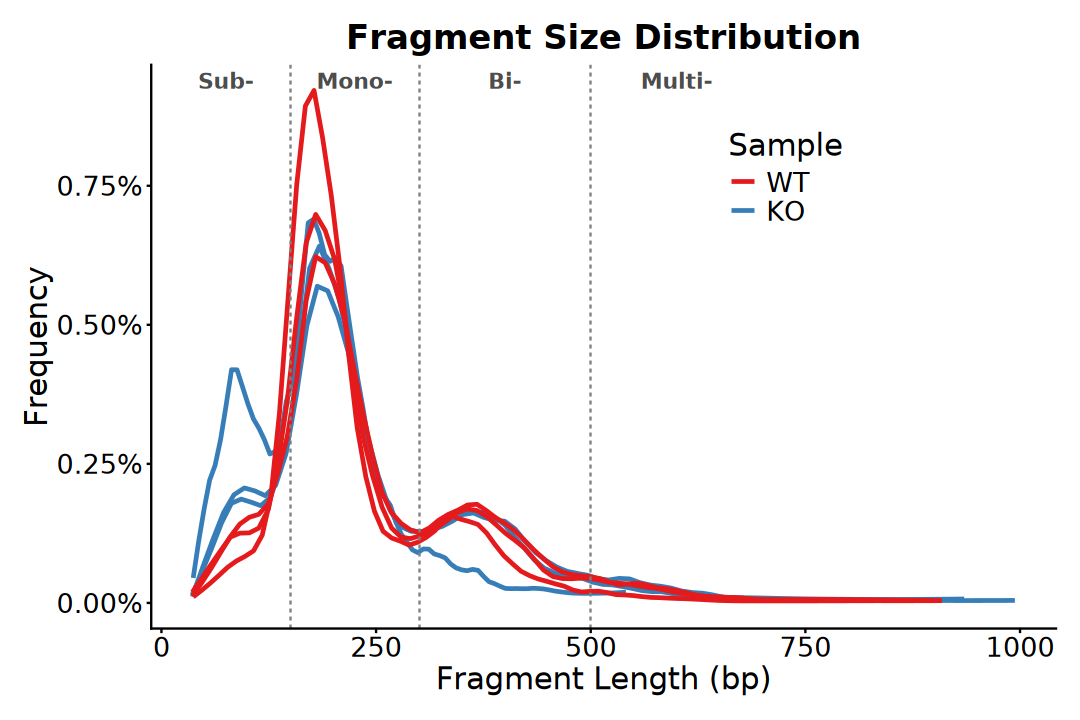

In [14]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(fragment_size, aes(x = Size, y = Freq, group = Sample)) +
    geom_smooth(
        aes(color = Group), formula = y ~ x, method = "loess", 
        na.rm = TRUE, se = FALSE, span = 0.1, linewidth = 1) +
    geom_vline(
        xintercept = c(150, 300, 500), 
        linetype = "dashed", color = "grey50", linewidth = 0.5) +
    annotate(
        "text", x = 75,  y = Inf, label = "Sub-",  vjust = 1.5, 
        size = 4.5, fontface = "bold", color = "grey30") +
    annotate(
        "text", x = 225, y = Inf, label = "Mono-", vjust = 1.5, 
        size = 4.5, fontface = "bold", color = "grey30") +
    annotate(
        "text", x = 400, y = Inf, label = "Bi-",   vjust = 1.5, 
        size = 4.5, fontface = "bold", color = "grey30") +
    annotate(
        "text", x = 600, y = Inf, label = "Multi-", vjust = 1.5, 
        size = 4.5, fontface = "bold", color = "grey30") +
    scale_y_continuous(
        limits = c(0, NA), labels = scales::percent_format()) +
    scale_color_brewer(
        palette = "Set1", labels = function(x) gsub("_", " ", x)) +
    labs(
        title = "Fragment Size Distribution", color = "Sample",
        x = "Fragment Length (bp)", y = "Frequency") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"), 
        legend.position = "inside",
        legend.position.inside = c(0.7, 0.8),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

## 3). TSS Enrichment Score

In [15]:
compute_tss_score <- function(
    matrix_file, sample, bs = 10, verbose = TRUE) {

    mat <- matrix_file |> 
        read.table(header = FALSE, sep = "\t", skip = 3) |>
        as.matrix()

    profile <- colMeans(mat, na.rm = TRUE)
    nbins <- length(profile)
    flank_bins <- 100 / bs

    background <- c(
        profile[1:flank_bins], 
        profile[(nbins - flank_bins + 1):nbins]) |> mean()

    norm_profile <- profile / background

    center_bin <- floor(nbins / 2)
    tss_score <- mean(norm_profile[center_bin:(center_bin + 1)])
    if (verbose) {
        message(sample, " TSS Enrichment Score: ", round(tss_score, 2))
    }

    data.frame(
        Position = seq(-2000, 1990, by = bs),
        Signal = profile, 
        Sample = sample, 
        TSS_Score = tss_score, 
        Label = paste0(sample, " (Score: ", round(tss_score, 2), ")"))
}

In [16]:
matrix_files <- file.path(data_dir, "04_output_atacseq", "08_deeptools") |>
    list.files(pattern = "\\.TSS\\.tsv$", full.names = TRUE) |>
    set_names(~ sub("(.*)\\.TSS\\.tsv$", "\\1", basename(.x)))

In [17]:
profiles_list <- imap(matrix_files, compute_tss_score)

mEF_Anp32e_KO_rep1 TSS Enrichment Score: 15.35

mEF_Anp32e_KO_rep2 TSS Enrichment Score: 11.85

mEF_Anp32e_KO_rep3 TSS Enrichment Score: 11.41

mEF_Anp32e_WT_rep1 TSS Enrichment Score: 6.66

mEF_Anp32e_WT_rep2 TSS Enrichment Score: 9.64

mEF_Anp32e_WT_rep3 TSS Enrichment Score: 7.97



In [18]:
profile_df <- do.call(rbind, profiles_list) |>
    mutate(Sample = sub("mEF_(.*)", "\\1", Sample)) |>
    left_join(coldata |> rownames_to_column("Sample"), by = "Sample") |>
    arrange(Group, Replicate) |>
    mutate(
        Sample = forcats::fct_inorder(as.character(Sample)),
        Label = forcats::fct_inorder(as.character(Label)))

head(profile_df)

,Position,Signal,Sample,TSS_Score,Label,Gene,Group,Replicate
,<dbl>,<dbl>,<fct>,<dbl>,<fct>,<chr>,<fct>,<fct>
1,-2000,12.39851,Anp32e_WT_rep1,6.655907,mEF_Anp32e_WT_rep1 (Score: 6.66),Anp32e,WT,rep1
2,-1990,12.41840,Anp32e_WT_rep1,6.655907,mEF_Anp32e_WT_rep1 (Score: 6.66),Anp32e,WT,rep1
3,-1980,12.41855,Anp32e_WT_rep1,6.655907,mEF_Anp32e_WT_rep1 (Score: 6.66),Anp32e,WT,rep1
4,-1970,12.41643,Anp32e_WT_rep1,6.655907,mEF_Anp32e_WT_rep1 (Score: 6.66),Anp32e,WT,rep1
5,-1960,12.40472,Anp32e_WT_rep1,6.655907,mEF_Anp32e_WT_rep1 (Score: 6.66),Anp32e,WT,rep1
6,-1950,12.39063,Anp32e_WT_rep1,6.655907,mEF_Anp32e_WT_rep1 (Score: 6.66),Anp32e,WT,rep1


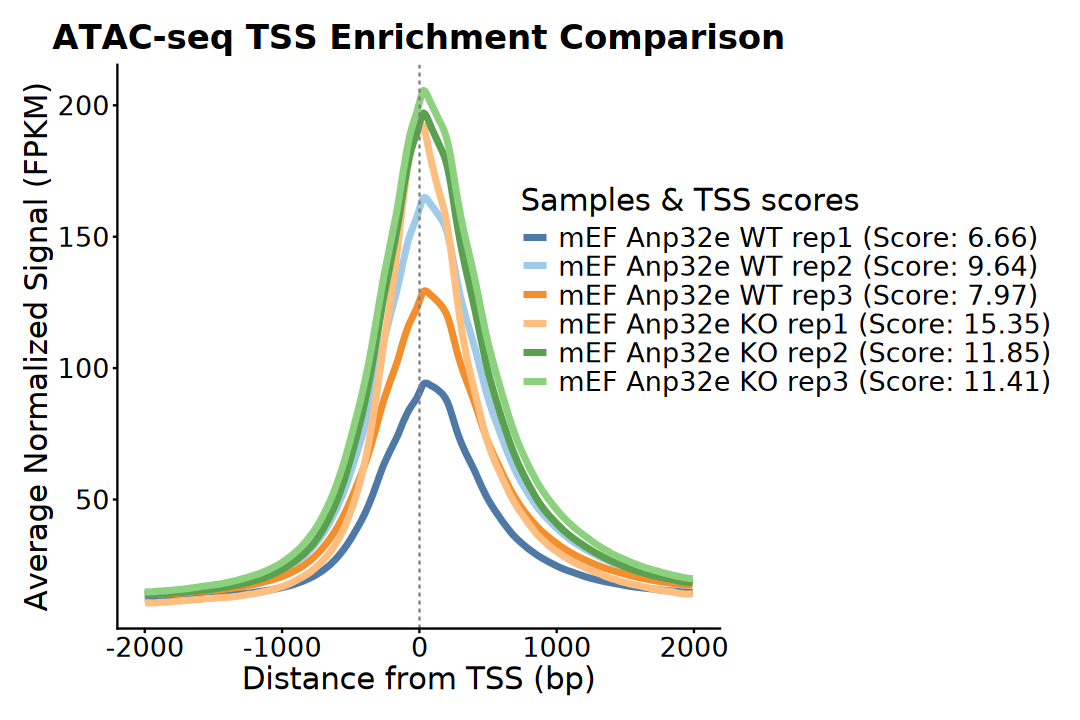

In [19]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(profile_df, aes(x = Position, y = Signal)) +
    geom_line(aes(color = Label), linewidth = 1.5) +
    geom_vline(
        xintercept = 0, linetype = "dashed", color = "gray50") +
    # scale_color_viridis_d(
    #     option = "viridis", 
    #     labels = function(x) gsub("_", " ", x)) +
    ggthemes::scale_color_tableau(
        palette = "Tableau 20", 
        labels = function(x) gsub("_", " ", x)) +
    labs(
        title = "ATAC-seq TSS Enrichment Comparison",
        color = "Samples & TSS scores",
        x = "Distance from TSS (bp)",
        y = "Average Normalized Signal (FPKM)") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 15, 1, 1), "line"),
        legend.position = "inside",
        legend.position.inside = c(1.1, 0.6),
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

## 4). Number of Peaks

In [ ]:
plot_df <- data.frame(
    sample = names(peaks_list), number = lengths(peaks_list)) |>
    left_join(coldata |> rownames_to_column("sample"), by = "sample") |>
    arrange(Group, Replicate) |>
    column_to_rownames("sample")

plot_df

,number,Gene,Group,Replicate
,<int>,<chr>,<fct>,<fct>
Anp32e_WT_rep1,39887,Anp32e,WT,rep1
Anp32e_WT_rep2,55431,Anp32e,WT,rep2
Anp32e_WT_rep3,50363,Anp32e,WT,rep3
Anp32e_KO_rep1,35133,Anp32e,KO,rep1
Anp32e_KO_rep2,48039,Anp32e,KO,rep2
Anp32e_KO_rep3,58794,Anp32e,KO,rep3


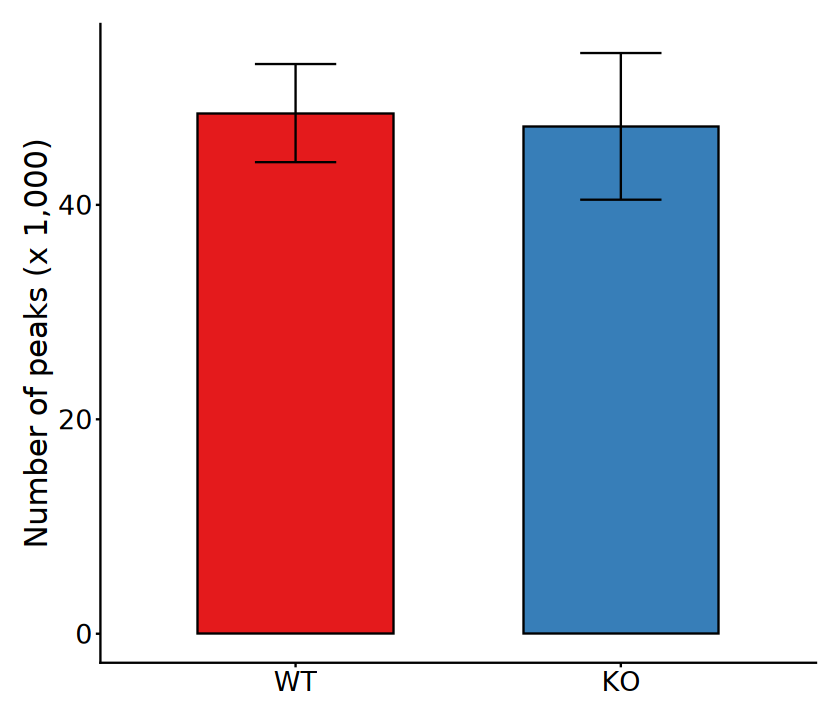

In [21]:
options(repr.plot.width = 7, repr.plot.height = 6)

ggplot(plot_df, aes(x = Group, y = number, fill = Group)) +
    geom_bar(
        stat = "summary", fun = "mean", color = "black", 
        width = 0.6) +
    stat_summary(
        fun.data = mean_se, geom = "errorbar", color = "black", 
        width = 0.25) +
    scale_y_continuous(labels = function(x) x / 1000) +
    scale_fill_brewer(palette = "Set1") +
    scale_color_brewer(palette = "Set1") +
    labs(x = NULL, y = "Number of peaks (x 1,000)") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.position = "none",
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

## 5). Replicate Consistency

In [22]:
# ------------------------------------------------------------------------------
# Function: summarize_peak_overlaps
#
# Description:
# Summarize the overlap composition of peak sets across replicates.
#
# Arguments:
#   peaks_list : named list of GRanges.
#   peaks      : short names used for display and ordering.
#                Default: rep1, rep2, ..., repN.
# ------------------------------------------------------------------------------
summarize_peak_overlaps <- function(
    peaks_list, peaks = paste0("rep", seq_along(peaks_list))) {

    names(peaks_list) <- peaks

    comb_levels <- unlist(
        lapply(seq_along(peaks), function(i) {
            combn(peaks, i, FUN = paste, collapse = "&")
        }), use.names = FALSE)

    ol <- lapply(peaks_list, function(gr) {
            names(gr) <- gr$name
            return(gr)
        }) |>
            ChIPpeakAnno::findOverlapsOfPeaks()

    ol$venn_cnt[, c(names(peaks_list), "Counts"), drop = FALSE] |>
        as.data.frame(stringsAsFactors = FALSE) |>
        dplyr::rename_with(~ peaks, .cols = names(peaks_list)) |>
        dplyr::rowwise() |>
        dplyr::mutate(
            Combination = {
                present <- peaks[c_across(dplyr::all_of(peaks)) == 1]
                if (length(present) == 0) {
                    NA_character_
                } else {
                    paste(present, collapse = "&")
                }
            }
        ) |>
        dplyr::ungroup() |>
        dplyr::mutate(
            Combination = factor(Combination, levels = comb_levels)) |>
        dplyr::filter(!is.na(Combination)) |>
        dplyr::select(Combination, Counts) |>
        as.data.frame()
}

In [23]:
replicate_peak_df <- dplyr::bind_rows(
    WT = summarize_peak_overlaps(
        peaks_list[coldata |> dplyr::filter(Group == "WT") |> rownames()]
    ),
    KO = summarize_peak_overlaps(
        peaks_list[coldata |> dplyr::filter(Group == "KO") |> rownames()]
    ),
    .id = "Group"
)

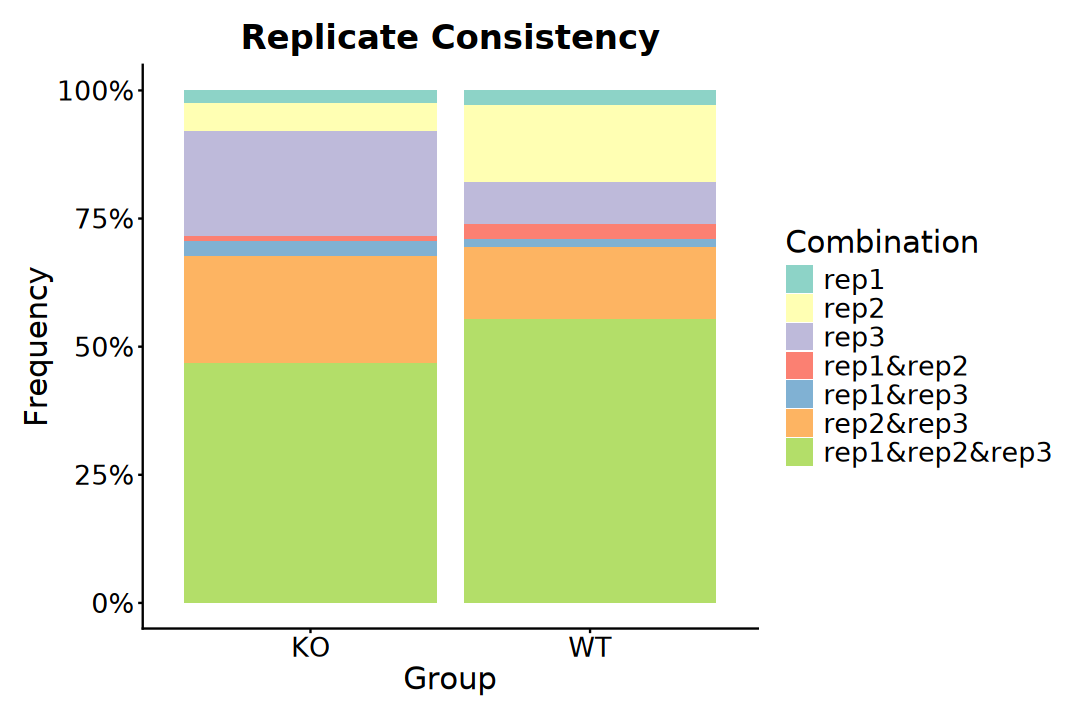

In [24]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(replicate_peak_df, aes(x = Group, y = Counts)) +
    geom_bar(aes(fill = Combination), stat = "identity", position = "fill") +
    scale_y_continuous(labels = scales::percent_format()) + 
    scale_fill_brewer(palette = "Set3") +
    labs(title = "Replicate Consistency", x = "Group", y = "Frequency") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.position = "right", 
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

# 4. Genome-wide Landscape

## 1). Global Signal

In [25]:
bin_means_df <- file.path(
    data_dir, "04_output_atacseq", "09_count", "bins_10kb.counts.tsv") |>
    read.table(header = TRUE, sep = "\t", comment.char = "") |>
    dplyr::rename(chr = X.chr) |>
    mutate(pos = paste0(chr, ":", start, "-", end)) |>
    select(-chr, -start, -end) |>
    column_to_rownames("pos") |>
    # filter(if_any(everything(), ~ var(.x, na.rm = TRUE) > 0))
    slice_max(
        order_by = apply(as.matrix(pick(everything())), 1, var), n = 2000
    )

bin_means_df[1:6, 1:2]

,mEF_Anp32e_KO_rep1,mEF_Anp32e_KO_rep2
,<dbl>,<dbl>
chr17:39840000-39850000,7705,11170
JH584304.1:50000-60000,2350,3968
JH584304.1:60000-70000,868,2182
JH584304.1:30000-40000,655,1289
chr11:3190000-3200000,549,1187
JH584304.1:40000-50000,502,1067


In [26]:
cor_mat <- cor(bin_means_df, method = "spearman")

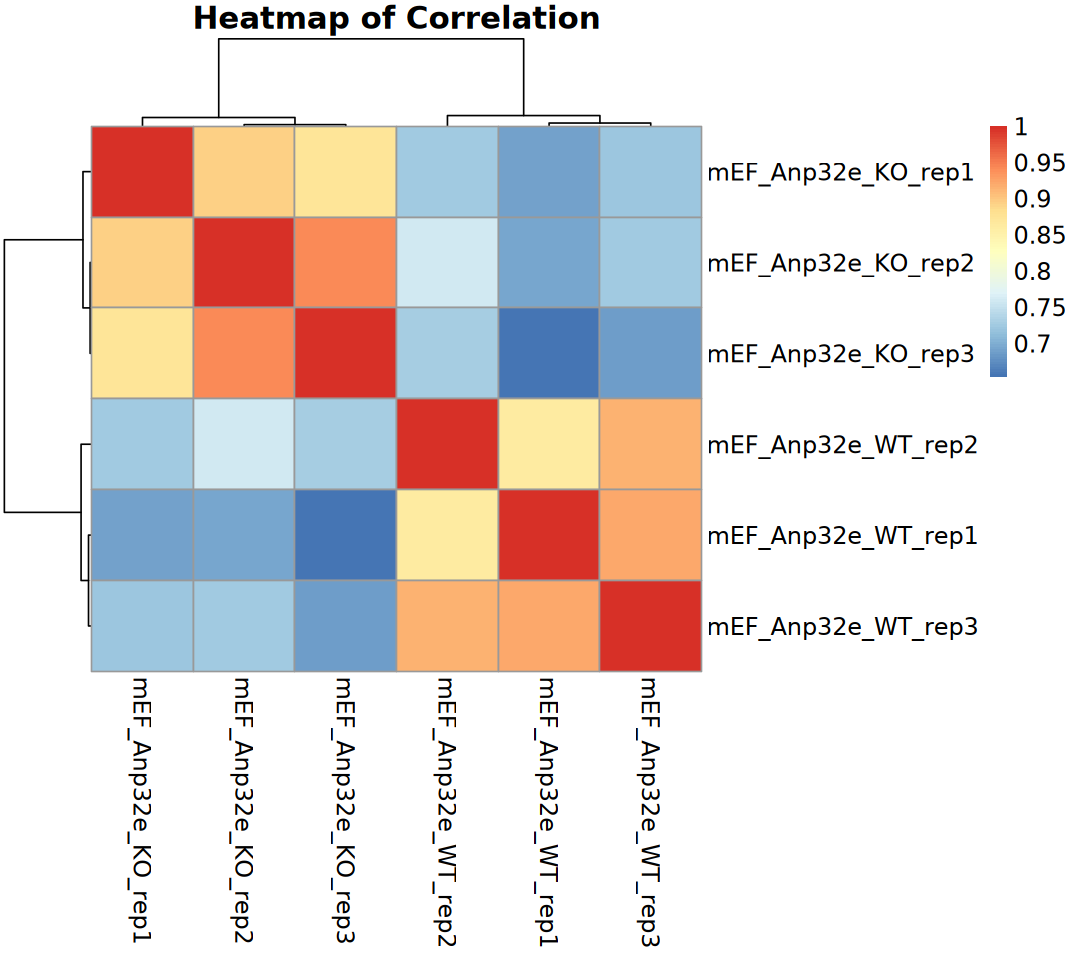

In [27]:
options(repr.plot.width = 9, repr.plot.height = 8)

pheatmap::pheatmap(
    as.matrix(cor_mat), 
    clustering_distance_rows = "correlation", 
    clustering_distance_cols = "correlation", 
    main = "Heatmap of Correlation", fontsize = 14, 
    show_colnames = TRUE, show_rownames = TRUE)

In [28]:
pca_df <- bin_means_df |> t() |>
    prcomp(center = TRUE, scale. = TRUE)

per_var <- round(pca_df$sdev^2 / sum(pca_df$sdev^2) * 100, 2)

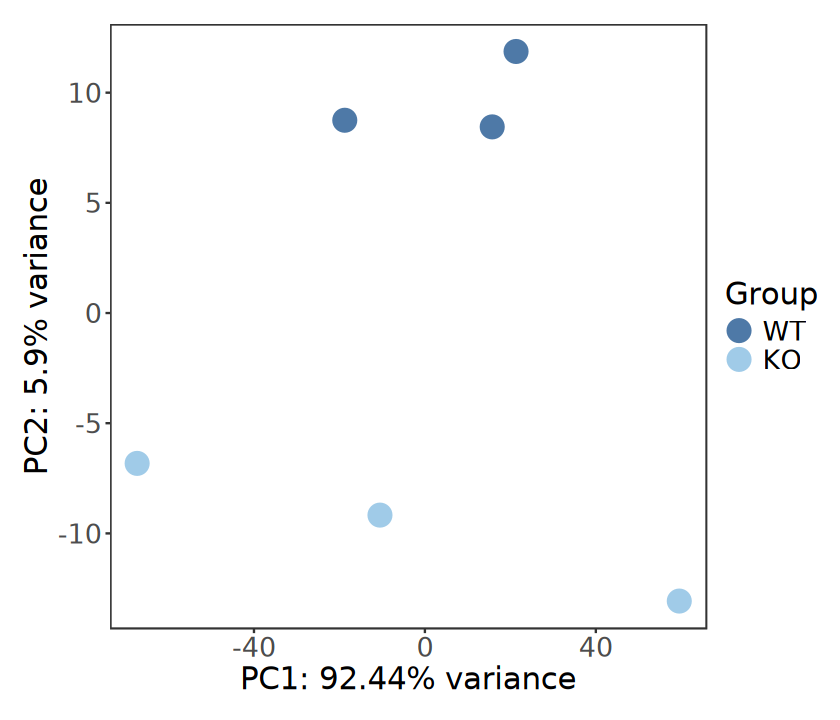

In [ ]:
options(repr.plot.width = 7, repr.plot.height = 6)

pca_df$x |> as.data.frame() |> 
    rownames_to_column(var = "Sample") |>
    mutate(Sample = sub("mEF_(.*)", "\\1", Sample)) |>
    left_join(coldata |> rownames_to_column("Sample"), by = "Sample") |>
ggplot(aes(PC1, PC2)) +
    geom_point(aes(color = Group), size = 6) +
    ggthemes::scale_color_tableau(palette = "Tableau 10") +
    xlab(paste0("PC1: ", per_var[1], "% variance")) +
    ylab(paste0("PC2: ", per_var[2], "% variance")) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.position = "right",
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

## 2). Metagene Profile

### a). deepTools

In [30]:
matrix_files <- file.path(data_dir, "04_output_atacseq", "08_deeptools") |>
    list.files(pattern = "\\.TSS\\.tsv$", full.names = TRUE) |>
    set_names(~ sub("mEF_(.*)\\.TSS\\.tsv$", "\\1", basename(.x)))

In [31]:
compute_matrix_mean <- function(file, sample) {
    read.table(file, header = FALSE, sep = "\t", skip = 3) |>
        as.matrix() |> colMeans(na.rm = TRUE)
}

In [32]:
profiles_list <- imap(matrix_files, compute_matrix_mean)

In [33]:
profiles_tss <- do.call(cbind, profiles_list) |>
    as.data.frame() |>
    mutate(Position = seq(-2000, 2000, length.out = 400)) |>
    pivot_longer(-Position, names_to = "Sample", values_to = "Signal") |>
    left_join(coldata |> rownames_to_column("Sample"), by = "Sample")

head(profiles_tss)

Position,Sample,Signal,Gene,Group,Replicate
<dbl>,<chr>,<dbl>,<chr>,<fct>,<fct>
-2000,Anp32e_KO_rep1,10.63770,Anp32e,KO,rep1
-2000,Anp32e_KO_rep2,13.82250,Anp32e,KO,rep2
-2000,Anp32e_KO_rep3,14.74527,Anp32e,KO,rep3
-2000,Anp32e_WT_rep1,12.39851,Anp32e,WT,rep1
-2000,Anp32e_WT_rep2,14.28914,Anp32e,WT,rep2
-2000,Anp32e_WT_rep3,13.77883,Anp32e,WT,rep3


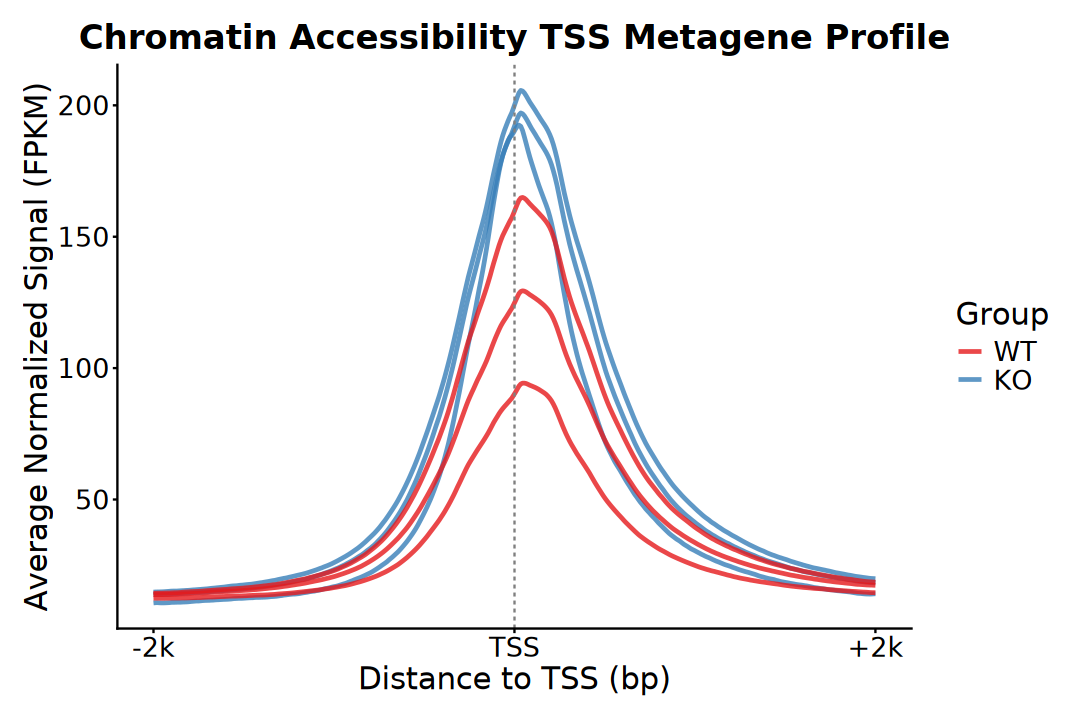

In [34]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(profiles_tss, aes(Position, Signal)) +
    geom_line(
        aes(color = Group, group = Sample), alpha = 0.8, linewidth = 1) +
    geom_vline(
        xintercept = 0, linetype = "dashed", color = "gray50") +
    scale_x_continuous(
        breaks = c(-2000, 0, 2000), labels = c("-2k", "TSS", "+2k")) +
    scale_color_brewer(palette = "Set1") +
    labs(
        title = "Chromatin Accessibility TSS Metagene Profile", 
        x = "Distance to TSS (bp)",
        y = "Average Normalized Signal (FPKM)") + 
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"), 
        panel.spacing = unit(2, "lines"), 
        strip.placement = "outside",
        strip.background = element_blank(),
        strip.text = element_text(size = 18),
        legend.position = "right",
        legend.box.margin = margin(l = 10),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16), 
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

### b). EnrichedHeatmap

In [35]:
suppressPackageStartupMessages(library(circlize))
suppressPackageStartupMessages(library(EnrichedHeatmap))

In [36]:
GENES <- gtf |> subset(
    type == "gene" & gene_type == "protein_coding", 
    select = c("gene_id", "gene_name", "gene_type")
)

In [37]:
# ~ 8 minutes
gene_mat_list <- lapply(
    signals_list, normalizeToMatrix, GENES, value_column = "score", 
    mean_mode = "w0", extend = 2000, w = 50, smooth = FALSE, 
    target_ratio = 0.4, background = NA)

In [ ]:
gene_mat_merged_list <- lapply(paste0("rep", 1:3), function(idx) {
    rbind.normalizedMatrix(
        gene_mat_list[[paste0("Anp32e_WT_", idx)]],
        gene_mat_list[[paste0("Anp32e_KO_", idx)]]
    )
})

names(gene_mat_merged_list) <- paste0("rep", 1:3)

In [39]:
partition <- c("Anp32e_WT", "Anp32e_KO") |>
    rep(each = length(GENES))

partition_cols <- c(Anp32e_WT  = "#1B9E77", Anp32e_KO = "#7570B3")

partition_lgd <- Legend(
    at = names(partition_cols), title = "Group",
    legend_gp = gpar(fill = partition_cols))

In [40]:
max_signal <- unlist(gene_mat_list, use.names = FALSE) |>
    abs() |> quantile(0.99, na.rm = TRUE)

unified_cols <- circlize::colorRamp2(
    c(0, max_signal), c("#F5F5F5", "#FF3F56"))

signal_lgd <- Legend(col_fun = unified_cols, title = "FPKM")

In [41]:
ht_list <- lapply(names(gene_mat_merged_list), function(idx) {
    EnrichedHeatmap(
        gene_mat_merged_list[[idx]], 
        name = idx, 
        column_title = idx, 
        col = unified_cols, 
        width = unit(4, "cm"), 
        show_row_names = FALSE, 
        axis_name = c("-2kb", "TSS", "TES", "+2kb"), 
        show_heatmap_legend = FALSE,
        top_annotation = HeatmapAnnotation(
            enriched = anno_enriched(
                gp = gpar(lwd = 2, col = partition_cols), 
                axis_param = list(gp = gpar(fontsize = 10))), 
            height = unit(3, "cm"), 
            show_legend = FALSE), 
        use_raster = TRUE)
})

In [42]:
ht_list <- Heatmap(
    partition, name = "Group", col = partition_cols, width = unit(3, "mm"),
    show_row_names = FALSE, show_heatmap_legend = FALSE) +
    Reduce(`+`, ht_list)

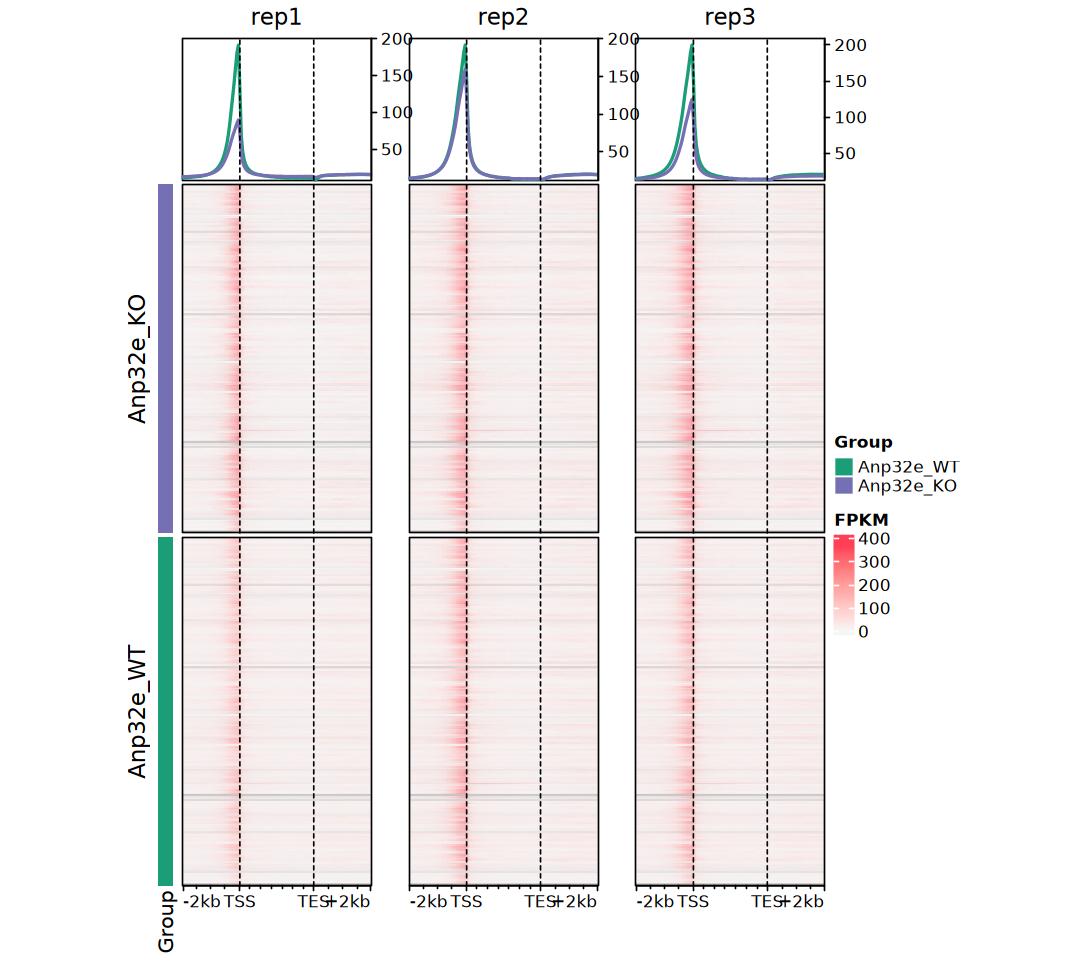

In [ ]:
options(repr.plot.width = 9, repr.plot.height = 8)

draw(
    ht_list, split = partition, heatmap_legend_side = "right", 
    annotation_legend_list = list(partition_lgd, signal_lgd),
    ht_gap = unit(c(2, rep(10, length(gene_mat_merged_list))), "mm"))

# 5. Peak Annotation

In [44]:
suppressPackageStartupMessages(library(ChIPseeker))

In [45]:
peaks_anno_list <- lapply(
    peaks_list, annotatePeak, tssRegion = c(-2000, 500), 
    TxDb = txdb, level = "transcript", verbose = FALSE, 
    genomicAnnotationPriority = c(
        "Promoter", "5UTR", "3UTR", "Exon", "Intron", 
        "Downstream", "Intergenic")
)

>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...


Warning message:
"`aes_string()` was deprecated in ggplot2 3.0.0.
ℹ Please use tidy evaluation idioms with `aes()`.
ℹ See also `vignette("ggplot2-in-packages")` for more information.
ℹ The deprecated feature was likely used in the ChIPseeker package.
  Please report the issue at <https://github.com/YuLab-SMU/ChIPseeker/issues>."


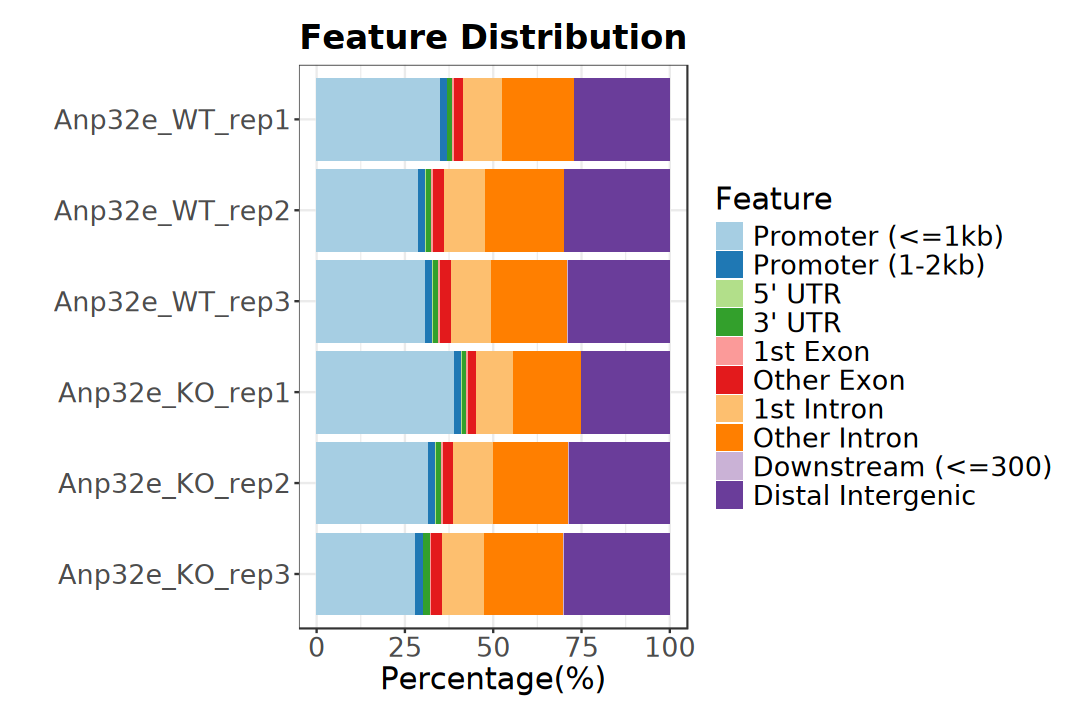

In [46]:
options(repr.plot.width = 9, repr.plot.height = 6)

plotAnnoBar(peaks_anno_list) +
    theme_bw() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"), 
        legend.position = "right", 
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

# 6. Differential Accessibility Regions

In [47]:
suppressPackageStartupMessages(library(DiffBind))
suppressPackageStartupMessages(library(BiocParallel))

In [ ]:
logfc_cutoff <- 0.5
p_cutoff <- 0.05

In [49]:
bam_files <- file.path(data_dir, "04_output_atacseq", "04_bam") |>
    list.files(pattern = "\\.bam$", full.names = TRUE) |>
    set_names(~ sub("mEF_(.*)\\.bam$", "\\1", basename(.x)))

peaks_files <- file.path(data_dir, "04_output_atacseq", "05_peaks") |>
    list.files(pattern = "peaks\\.narrowPeak$", full.names = TRUE) |>
    set_names(~ sub("mEF_(.*)_peaks\\.narrowPeak$", "\\1", basename(.x)))

In [50]:
coldata <- data.frame(sample = names(signals_files)) |>
    separate(
        sample, into = c("Gene", "Group", "Replicate"),
        sep = "_", remove = FALSE) |>
    mutate(
        Group = factor(Group, levels = c("WT", "KO")),
        Replicate = factor(Replicate)) |>
    arrange(Group, Replicate) |>
    column_to_rownames("sample")

coldata

,Gene,Group,Replicate
,<chr>,<fct>,<fct>
Anp32e_WT_rep1,Anp32e,WT,rep1
Anp32e_WT_rep2,Anp32e,WT,rep2
Anp32e_WT_rep3,Anp32e,WT,rep3
Anp32e_KO_rep1,Anp32e,KO,rep1
Anp32e_KO_rep2,Anp32e,KO,rep2
Anp32e_KO_rep3,Anp32e,KO,rep3


In [51]:
sample_sheet <- data.frame(SampleID = names(bam_files)) |>
    separate(
        SampleID, into = c("Gene", "Condition", "Replicate"), 
        sep = "_", remove = FALSE) |>
    mutate(
        Tissue = "mEF",
        Factor = "ATAC",
        Condition = factor(Condition, levels = c("WT", "KO")),
        Treatment = NA_character_,
        Replicate = as.numeric(sub("rep", "", Replicate)), 
        bamReads = bam_files, Peaks = peaks_files,
        PeakCaller = "narrow") |>
    select(
        SampleID, Tissue, Factor, Condition, Treatment, Replicate, 
        bamReads, Peaks, PeakCaller)

sample_sheet |> dplyr::select(-any_of(c("Peaks", "bamReads")))

SampleID,Tissue,Factor,Condition,Treatment,Replicate,PeakCaller
<chr>,<chr>,<chr>,<fct>,<chr>,<dbl>,<chr>
Anp32e_KO_rep1,mEF,ATAC,KO,NA,1,narrow
Anp32e_KO_rep2,mEF,ATAC,KO,NA,2,narrow
Anp32e_KO_rep3,mEF,ATAC,KO,NA,3,narrow
Anp32e_WT_rep1,mEF,ATAC,WT,NA,1,narrow
Anp32e_WT_rep2,mEF,ATAC,WT,NA,2,narrow
Anp32e_WT_rep3,mEF,ATAC,WT,NA,3,narrow


In [52]:
write.csv(
    sample_sheet, file.path(
        data_dir, "04_output_atacseq", "01_stats", "diffbind_sample.csv"), 
    quote = FALSE, row.names = FALSE)

In [53]:
dbObj <- dba(sampleSheet = file.path(
    data_dir, "04_output_atacseq", "01_stats", "diffbind_sample.csv"))
dbObj

Anp32e_KO_rep1 mEF ATAC KO  1 narrow



Anp32e_KO_rep2 mEF ATAC KO  2 narrow

Anp32e_KO_rep3 mEF ATAC KO  3 narrow

Anp32e_WT_rep1 mEF ATAC WT  1 narrow

Anp32e_WT_rep2 mEF ATAC WT  2 narrow

Anp32e_WT_rep3 mEF ATAC WT  3 narrow



6 Samples, 58804 sites in matrix (76513 total):
              ID Tissue Factor Condition Replicate Intervals
1 Anp32e_KO_rep1    mEF   ATAC        KO         1     35791
2 Anp32e_KO_rep2    mEF   ATAC        KO         2     48853
3 Anp32e_KO_rep3    mEF   ATAC        KO         3     59771
4 Anp32e_WT_rep1    mEF   ATAC        WT         1     40642
5 Anp32e_WT_rep2    mEF   ATAC        WT         2     56397
6 Anp32e_WT_rep3    mEF   ATAC        WT         3     51280

In [54]:
dbObj <- dba.blacklist(dbObj, blacklist = DBA_BLACKLIST_MM10, greylist = FALSE)

Genome detected: Mmusculus.UCSC.mm10

Applying blacklist...

Removed: 4888 of 292734 intervals.

Removed: 1243 merged (of 76513) and 940 (of 58804) consensus.



In [55]:
# Force registration of a multi-core environment with only 4 workers (cores).
# register(MulticoreParam(workers = 4))

# Set the number of CPU cores for parallel processing to 6
print(dbObj$config$cores)
dbObj$config$cores <- 4
# Check (or return) the current status of parallel execution (TRUE/FALSE)
print(dbObj$config$RunParallel)

[1] 16
[1] TRUE


In [56]:
# Count reads in binding site intervals
# (4 cores: ~10 min, memory consumption, 8G)
dbObj <- dba.count(dbObj, bUseSummarizeOverlaps = TRUE, bParallel = TRUE)

dbObj

Computing summits...

Re-centering peaks...



6 Samples, 57862 sites in matrix:
              ID Tissue Factor Condition Replicate    Reads FRiP
1 Anp32e_KO_rep1    mEF   ATAC        KO         1  6121528 0.24
2 Anp32e_KO_rep2    mEF   ATAC        KO         2 13062964 0.24
3 Anp32e_KO_rep3    mEF   ATAC        KO         3 20319423 0.24
4 Anp32e_WT_rep1    mEF   ATAC        WT         1 23442585 0.12
5 Anp32e_WT_rep2    mEF   ATAC        WT         2 19596165 0.20
6 Anp32e_WT_rep3    mEF   ATAC        WT         3 25152538 0.16

In [57]:
# Normalization
dbObj <- dba.normalize(
    dbObj, normalize = DBA_NORM_TMM, library = DBA_LIBSIZE_PEAKREADS, 
    background = FALSE)

In [58]:
# Sets up contrasts for differential binding affinity analysis
dbObj <- dba.contrast(
    dbObj, categories = DBA_TISSUE, minMembers = 3, 
    reorderMeta = list(Condition = "WT"))

dbObj

Warning message:
"No contrasts added. There must be at least two sample groups with at least three replicates."


6 Samples, 57862 sites in matrix:
              ID Tissue Factor Condition Replicate    Reads FRiP
1 Anp32e_KO_rep1    mEF   ATAC        KO         1  6121528 0.24
2 Anp32e_KO_rep2    mEF   ATAC        KO         2 13062964 0.24
3 Anp32e_KO_rep3    mEF   ATAC        KO         3 20319423 0.24
4 Anp32e_WT_rep1    mEF   ATAC        WT         1 23442585 0.12
5 Anp32e_WT_rep2    mEF   ATAC        WT         2 19596165 0.20
6 Anp32e_WT_rep3    mEF   ATAC        WT         3 25152538 0.16

In [59]:
# Perform differential binding affinity analysis
dbObj <- dba.analyze(dbObj, method = DBA_DESEQ2)
dba.show(dbObj, bContrasts = TRUE)

Forming default model design and contrast(s)...

Computing results names...

Analyzing...

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates



,Factor,Group,Samples,Group2,Samples2,DB.DESeq2
,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
1,Condition,KO,3,WT,3,7502


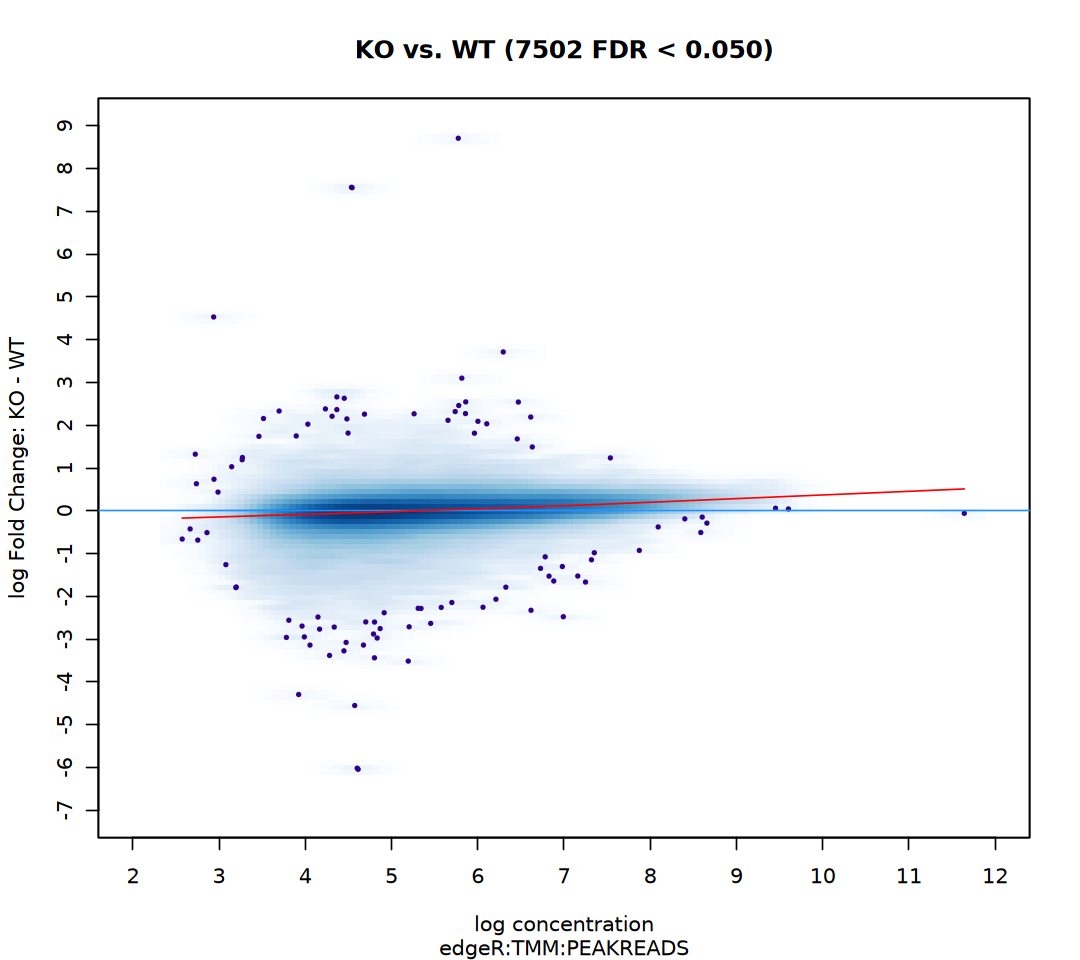

In [60]:
options(repr.plot.width = 9, repr.plot.height = 8)

dba.plotMA(dbObj, sub = "edgeR:TMM:PEAKREADS", bSignificant = FALSE)

In [61]:
# Generate a report for a differential binding affinity analysis
diffbind_result <- dba.report(
    dbObj, method = DBA_DESEQ2, contrast = 1, 
    fold = 0, th = 1, bUsePval = FALSE)

diffbind_result$result = case_when(
    diffbind_result$FDR < p_cutoff & 
        diffbind_result$Fold >  logfc_cutoff ~ "Gain",
    diffbind_result$FDR < p_cutoff & 
        diffbind_result$Fold < -logfc_cutoff ~ "Loss",
    TRUE ~ "NS") |> 
    factor(levels = c("Gain", "Loss", "NS"))

diffbind_result

GRanges object with 57862 ranges and 7 metadata columns:
        seqnames              ranges strand |      Conc   Conc_KO   Conc_WT
           <Rle>           <IRanges>  <Rle> | <numeric> <numeric> <numeric>
   8661    chr11   57091308-57091708      * |   6.29542   7.20525   3.25061
   7085    chr10 112123821-112124221      * |   6.99206   5.07423   7.78729
  16010    chr14   13022768-13023168      * |   6.47057   7.25385   4.62872
  35146     chr3   98427475-98427875      * |   6.61730   4.97460   7.36554
   7018    chr10 109903805-109904205      * |   6.61432   7.34855   5.04298
    ...      ...                 ...    ... .       ...       ...       ...
  43513     chr5 145059424-145059824      * |   4.02062   4.04767   3.99306
  13028    chr12 116152858-116153258      * |   4.58295   4.56392   4.60173
  26415    chr18   67324333-67324733      * |   4.86559   4.84807   4.88291
   4528    chr10   13250037-13250437      * |   5.58248   5.57733   5.58762
   1783     chr1   90051215-900

In [62]:
res_tab <- table(diffbind_result$result)

message(
    "Differential accessibility peaks summary (DiffBind):\n",
    "---------------------------------------------------\n",
    "Gain (higher accessibility) : ", res_tab["Gain"], "\n",
    "Loss (lower accessibility)  : ", res_tab["Loss"], "\n",
    "Not significant             : ", res_tab["NS"], "\n",
    "---------------------------------------------------"
)

Differential accessibility peaks summary (DiffBind):
---------------------------------------------------
Gain (higher accessibility) : 2176
Loss (lower accessibility)  : 3207
Not significant             : 52479
---------------------------------------------------



In [63]:
dar_peaks <- list(
    Gain = diffbind_result[diffbind_result$result == "Gain", ], 
    Loss = diffbind_result[diffbind_result$result == "Loss", ])

In [64]:
dar_peaks <- lapply(
    dar_peaks, annotatePeak, tssRegion = c(-2000, 500), 
    TxDb = txdb, level = "transcript", verbose = FALSE, 
    genomicAnnotationPriority = c(
        "Promoter", "5UTR", "3UTR", "Exon", "Intron", 
        "Downstream", "Intergenic")
)

>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...


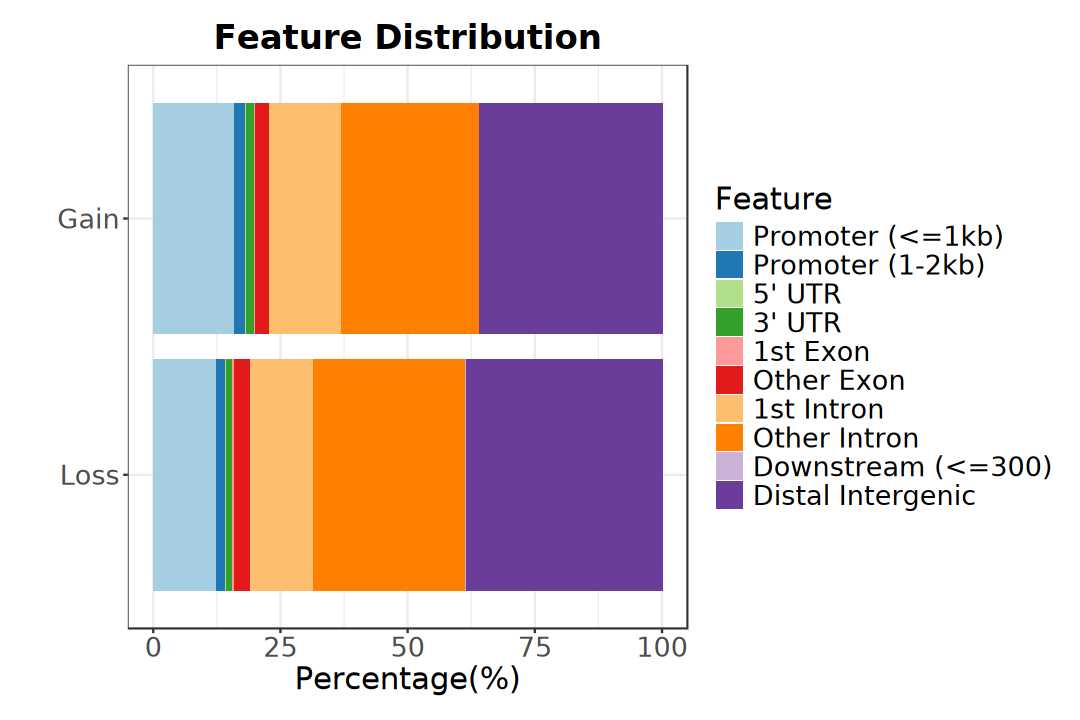

In [65]:
options(repr.plot.width = 9, repr.plot.height = 6)

plotAnnoBar(dar_peaks) +
    theme_bw() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"), 
        legend.position = "right", 
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

In [66]:
peaks_anno_list <- lapply(dar_peaks, function(anno) {
    anno@anno |> 
    as.data.frame() |>
    mutate(
        Category = case_when(
            grepl("Promoter", annotation) ~ "Promoter",
            grepl("UTR|Exon", annotation) ~ "Exon",
            grepl("Intron", annotation) ~ "Intron",
            grepl("Downstream|Intergenic", annotation) ~ "Intergenic",
            TRUE ~ as.character(annotation)
        )) |> 
    as("GRanges")
})

In [67]:
promoter_genes <- lapply(peaks_anno_list, function(anno) {
    anno |> as.data.frame() |>
        filter(Category == "Promoter", !is.na(geneId), geneId != "") |>
        distinct(geneId) |>
        pull(geneId) |>
        unique()
})

# 7. Function Analysis

In [68]:
suppressPackageStartupMessages(library(ChIPseeker))
suppressPackageStartupMessages(library(org.Mm.eg.db))
suppressPackageStartupMessages(library(clusterProfiler))

In [69]:
add_ENTREZID <- function(
    query_ids, orgdb, fromType = "ENSEMBL", toType = c("SYMBOL", "ENTREZID"), 
    ignoreVersion = FALSE) {

    if(fromType == "ENSEMBL" & ignoreVersion) {
        query_ids <- sub("\\..*$", "", query_ids) |> unique()
    }

    gene_map <- clusterProfiler::bitr(
        query_ids, OrgDb = orgdb, fromType = fromType, toType = toType, 
        drop = FALSE)

    idx <- match(query_ids, gene_map[[fromType]])

    res <- data.frame(
        fromType = query_ids, stringsAsFactors = FALSE)

    for (col in toType) {
        res[[col]] <- gene_map[[col]][idx]
    }

    return(res)
}

In [70]:
promoter_genes <- lapply(promoter_genes, add_ENTREZID,
    orgdb = org.Mm.eg.db, fromType = "ENSEMBL", 
    toType = c("SYMBOL", "ENTREZID"), 
    ignoreVersion = TRUE)

'select()' returned 1:1 mapping between keys and columns

Warning message in clusterProfiler::bitr(query_ids, OrgDb = orgdb, fromType = fromType, :
"14.1% of input gene IDs are fail to map..."
'select()' returned 1:many mapping between keys and columns

Warning message in clusterProfiler::bitr(query_ids, OrgDb = orgdb, fromType = fromType, :
"18.45% of input gene IDs are fail to map..."


In [71]:
genes_list <- lapply(promoter_genes, \(x) x$SYMBOL |> na.omit() |> unique())

all_symbols <- AnnotationDbi::keys(org.Mm.eg.db, keytype = "SYMBOL")

In [72]:
ego_compare <- compareCluster(
    geneCluster = genes_list, fun = enrichGO, universe = all_symbols, 
    OrgDb = org.Mm.eg.db, ont = "ALL", keyType = 'SYMBOL', 
    pAdjustMethod = "BH", pvalueCutoff = 0.01, qvalueCutoff = 0.05, 
    minGSSize = 10, maxGSSize = 500, readable = TRUE)

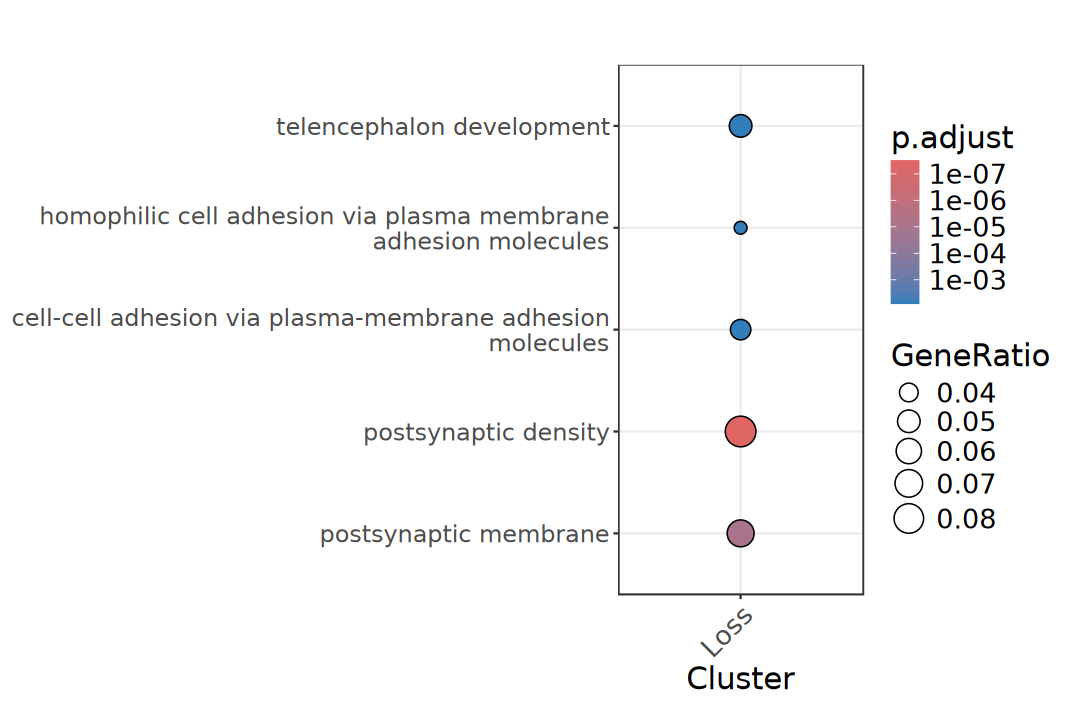

In [73]:
options(repr.plot.width = 9, repr.plot.height = 6)

dotplot(ego_compare, showCategory = 5, label_format = 50) +
    theme_bw() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text.x = element_text(size = 16, angle = 45, hjust = 1), 
        axis.text.y = element_text(size = 14))

In [74]:
genes_list <- lapply(promoter_genes, \(x) x$ENTREZID |> na.omit() |> unique())

all_entrezid <- AnnotationDbi::keys(org.Mm.eg.db, keytype = "ENTREZID")

In [75]:
ekegg_compare <- compareCluster(
    geneCluster = genes_list, fun = enrichKEGG, universe = all_entrezid, 
    organism = "mmu", 
    pAdjustMethod = "BH", pvalueCutoff = 0.01, qvalueCutoff = 0.05, 
    minGSSize = 10, maxGSSize = 500)

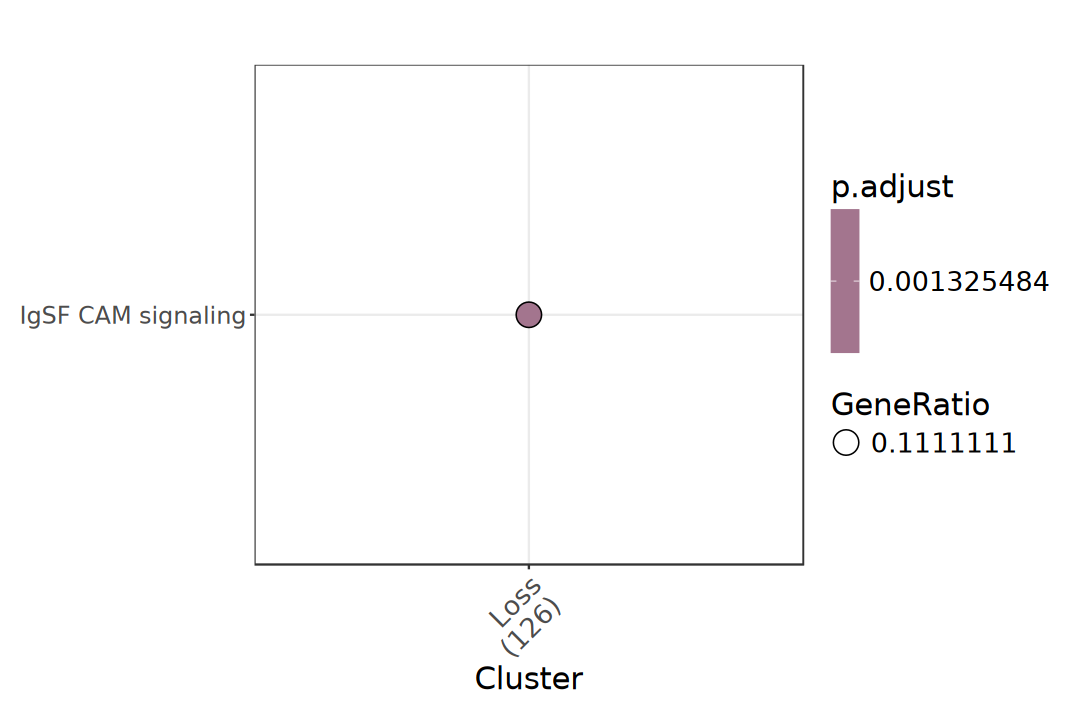

In [76]:
options(repr.plot.width = 9, repr.plot.height = 6)

dotplot(ekegg_compare, showCategory = 5, label_format = 40) +
    theme_bw() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text.x = element_text(size = 16, angle = 45, hjust = 1), 
        axis.text.y = element_text(size = 14))

# * Reference